# 02 — Exploratory Data Analysis (EDA)

In [8]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

CLEAN = ROOT / "data" / "processed" / "superstore_cleaned.csv"
RAW = ROOT / "data" / "raw" / "Sample - Superstore.csv"

FILE = CLEAN if CLEAN.exists() else RAW

print("Project root:", ROOT)
print("Cleaned file exists:", CLEAN.exists())
print("Raw file exists:", RAW.exists())
print("Selected file:", FILE)

if not FILE.exists():
    raise FileNotFoundError(
        f"CSV not found: {FILE}. Check the filename and data/raw folder."
    )

for enc in ("utf-8-sig", "cp1252", "latin1"):
    try:
        df = pd.read_csv(FILE, encoding=enc)
        print("Loaded successfully using:", enc)
        break
    except UnicodeDecodeError:
        continue
else:
    raise ValueError("Could not decode the CSV file.")

df.columns = [str(c).strip() for c in df.columns]

for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

for col in ["Sales", "Profit", "Quantity", "Discount"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
display(df.head())


Project root: A:\Data Analyst\Customer-profitability-intellegence
Cleaned file exists: True
Raw file exists: True
Selected file: A:\Data Analyst\Customer-profitability-intellegence\data\processed\superstore_cleaned.csv
Loaded successfully using: utf-8-sig
Rows: 9,994 | Columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,NaT,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,NaT,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,NaT,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
kpis = pd.DataFrame({
    "Metric": ["Rows", "Total Sales", "Total Profit", "Profit Margin %", "Distinct Orders", "Distinct Customers"],
    "Value": [len(df), total_sales, total_profit,
              total_profit / total_sales * 100 if total_sales else np.nan,
              df["Order ID"].nunique() if "Order ID" in df.columns else np.nan,
              df["Customer ID"].nunique() if "Customer ID" in df.columns else np.nan]
})
display(kpis)


,Metric,Value
0,Rows,9.994000e+03
1,Total Sales,2.297201e+06
2,Total Profit,2.863970e+05
3,Profit Margin %,1.246722e+01
4,Distinct Orders,5.009000e+03
5,Distinct Customers,7.930000e+02


,Category,Sales,Profit,Profit Margin %
2,Technology,836154.0330,145454.9481,17.395712
1,Office Supplies,719047.0320,122490.8008,17.035158
0,Furniture,741999.7953,18451.2728,2.486695


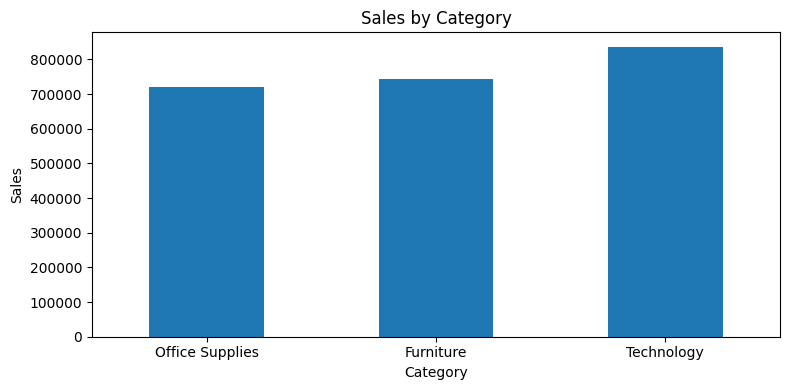

In [4]:
if "Category" in df.columns:
    category = df.groupby("Category", dropna=False).agg(Sales=("Sales","sum"), Profit=("Profit","sum")).reset_index()
    category["Profit Margin %"] = np.where(category["Sales"] != 0, category["Profit"] / category["Sales"] * 100, np.nan)
    display(category.sort_values("Profit", ascending=False))
    category.sort_values("Sales").plot(x="Category", y="Sales", kind="bar", legend=False, title="Sales by Category", figsize=(8,4))
    plt.ylabel("Sales"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()


,Sub-Category,Sales,Profit
16,Tables,206965.5320,-17725.4811
4,Bookcases,114879.9963,-3472.5560
15,Supplies,46673.5380,-1189.0995
8,Fasteners,3024.2800,949.5182
11,Machines,189238.6310,3384.7569
10,Labels,12486.3120,5546.2540
2,Art,27118.7920,6527.7870
7,Envelopes,16476.4020,6964.1767
9,Furnishings,91705.1640,13059.1436
1,Appliances,107532.1610,18138.0054


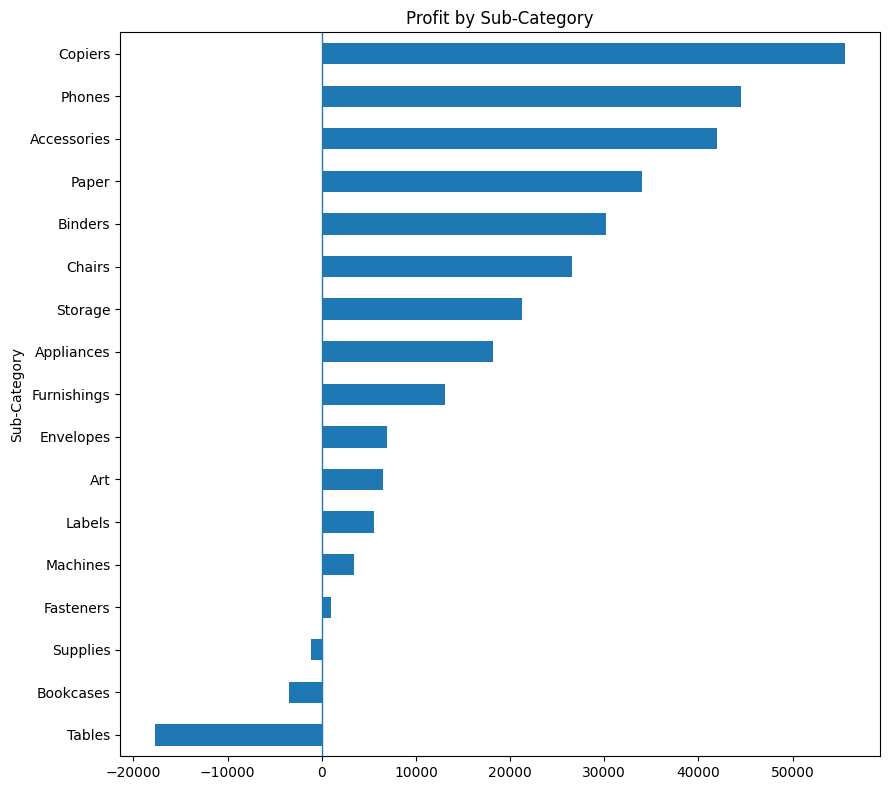

In [5]:
if "Sub-Category" in df.columns:
    sub = df.groupby("Sub-Category", dropna=False).agg(Sales=("Sales","sum"), Profit=("Profit","sum")).reset_index().sort_values("Profit")
    display(sub)
    sub.plot(x="Sub-Category", y="Profit", kind="barh", legend=False, title="Profit by Sub-Category", figsize=(9,8))
    plt.axvline(0, linewidth=1); plt.tight_layout(); plt.show()


,Region,Sales,Profit,Profit Margin %
3,West,725457.8245,108418.4489,14.944831
1,East,678781.2400,91522.7800,13.483399
2,South,391721.9050,46749.4303,11.934342
0,Central,501239.8908,39706.3625,7.921629


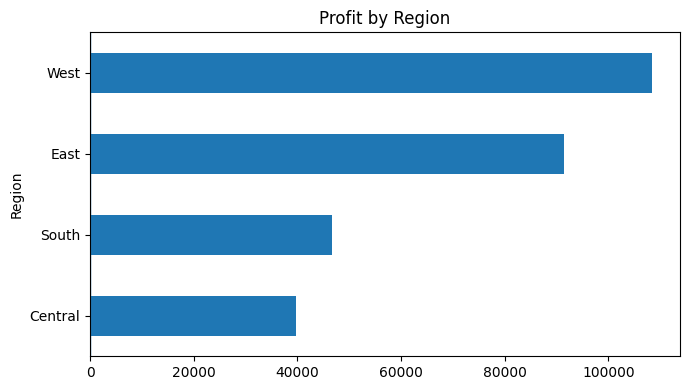

In [6]:
if "Region" in df.columns:
    region = df.groupby("Region", dropna=False).agg(Sales=("Sales","sum"), Profit=("Profit","sum")).reset_index().sort_values("Profit", ascending=False)
    region["Profit Margin %"] = np.where(region["Sales"] != 0, region["Profit"] / region["Sales"] * 100, np.nan)
    display(region)
    region.sort_values("Profit").plot(x="Region", y="Profit", kind="barh", legend=False, title="Profit by Region", figsize=(7,4))
    plt.axvline(0, linewidth=1); plt.tight_layout(); plt.show()


,Order Month,Sales,Profit
0,2014-01-01,4923.616,1267.1885
1,2014-02-01,3610.402,706.7725
2,2014-03-01,8048.773,-84.0777
3,2014-04-01,16040.811,2518.7970
4,2014-05-01,9288.864,499.5860


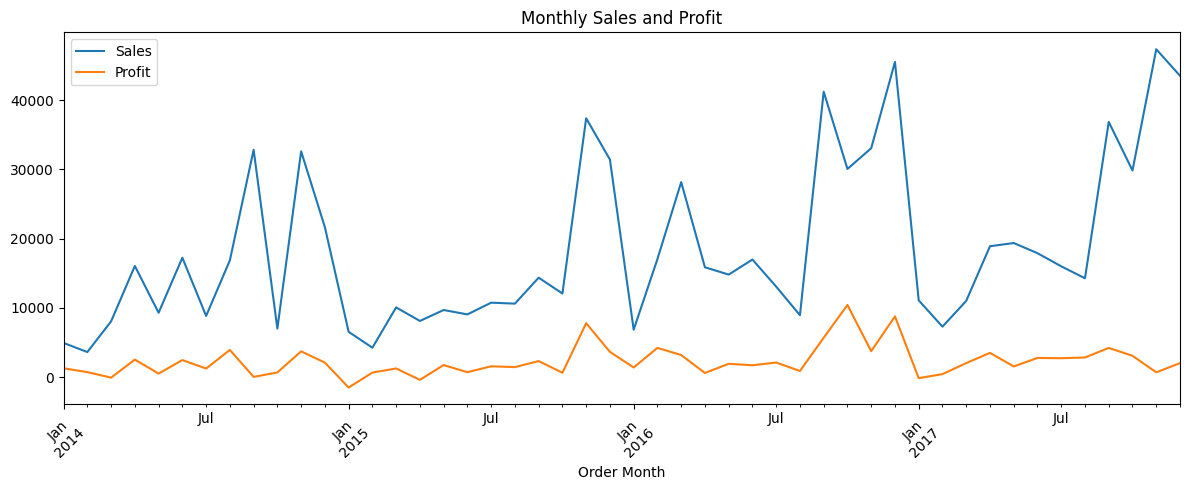

In [7]:
if "Order Date" in df.columns:
    temp = df.dropna(subset=["Order Date"]).copy()
    temp["Order Month"] = temp["Order Date"].dt.to_period("M").dt.to_timestamp()
    monthly = temp.groupby("Order Month").agg(Sales=("Sales","sum"), Profit=("Profit","sum")).reset_index().sort_values("Order Month")
    display(monthly.head())
    monthly.plot(x="Order Month", y=["Sales","Profit"], title="Monthly Sales and Profit", figsize=(12,5))
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()
